# Phase 4 — Switch-point and CMI weighted knowledge distillation
**Switch-Point and Code-Mixing-Index Weighted Knowledge Distillation for Hindi-English Sentiment Analysis**

Arms (all share the same teacher, transfer set, student init and hyperparameters):
- `ce_only`   : no teacher (reference)
- `kd_plain`  : logit + hidden-state KD (the baseline every other arm is compared with)
- `kd_cmi`    : KD terms weighted per EXAMPLE by CMI (more weight on more-mixed sentences)
- `kd_switch` : hidden-state loss weighted per TOKEN, 2x on wordpieces next to a language switch
- `kd_both`   : both weightings
- optional `kd_swmask`, `kd_randmask`: switch-targeted vs random masking of the student input (add to RUN_ARMS)

**Pre-specified endpoints** (reported separately from exploratory bins): P1 overall macro-F1, P2 top CMI tercile, P3 top switch-density tercile,
each as (arm − kd_plain) with paired bootstrap CIs.

Needs Phase 2 outputs (teacher). `STUDENT_LAYERS=3` by default: Phase 3's 6-layer student lost only about 1 F1, leaving no room to show an improvement.
Time (estimate, unmeasured): about 6-8 min per kd arm per seed on a T4 with the default 20k transfer rows. 5 arms x 3 seeds is roughly 1.5 h.
Copy everything under `════ REPORT BACK ════` markers and send it back.

In [5]:
from pathlib import Path
from safetensors import safe_open

def ok(d):
    try:
        with safe_open(str(Path(d)/"model.safetensors"), framework="pt") as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print("unreadable:", d, str(e)[:60]); return False

for d in ["/content/phase2_outputs/teacher_best",
          "/content/drive/MyDrive/mixing_aware_kd/phase2/teacher_best"]:
    if Path(d).exists() and ok(d):
        TEACHER_DIR = Path(d); print("Using", TEACHER_DIR); break
else:
    print("No readable copy found: see the retrain steps below")

Using /content/phase2_outputs/teacher_best


In [6]:
# CELL 1: Imports, config, locate Phase 2 outputs
import os, sys, re, json, time, copy, random, shutil, subprocess, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ── Config ───────────────────────────────────────────────────────────────────
SEEDS          = [13, 42, 2024]                 # use 5 seeds for the final paper numbers
STUDENT_LAYERS = 3                              # 3 leaves measurable headroom (Phase 3's 6 layers lost only ~1 F1); 6 matches Phase 3
LAYER_MAPS     = {2: [5, 11], 3: [3, 7, 11], 4: [2, 5, 8, 11], 6: [1, 3, 5, 7, 9, 11]}   # teacher layers copied into the student;
LAYER_MAP      = LAYER_MAPS[STUDENT_LAYERS]     # last one is always 11 so the final student layer matches the teacher's
RUN_ARMS       = ["ce_only", "kd_plain", "kd_cmi", "kd_switch", "kd_both"]   # optional extras: "kd_swmask", "kd_randmask"
EPOCHS       = 3
LR           = 5e-5
BATCH        = 32
MAXLEN       = 160
WARMUP_FRAC  = 0.10
WEIGHT_DECAY = 0.01
TEMP         = 2.0
# Weighting hyperparameters: fixed in advance, NOT tuned on the test set.
LAMBDA_CMI   = 0.3      # example weight = clip(1 + LAMBDA_CMI * z(CMI), W_MIN, W_MAX), then rescaled to mean 1
W_MIN, W_MAX = 0.5, 2.0
MU_SWITCH    = 1.0      # hidden-state loss on switch-adjacent wordpieces is weighted (1 + MU_SWITCH) = 2x
P_MASK_SW    = 0.3      # (optional arms) probability of [MASK]ing a switch-adjacent wordpiece in the STUDENT input
TRIM_VOCAB       = True                          # Baseline B showed trimming costs nothing measurable
VOCAB_MIN_COUNT  = 2
MIN_LANG_TOKENS  = 4
N_TRANSFER_MAX   = 20000                         # unlabeled HingLID rows used for KD (None = all 37.6k, ~1.8x slower)
N_BOOT       = 1000
MIN_BIN_N    = 50
USE_DRIVE    = True
SAVE_STUDENTS = True

def _arm(**kw):
    base = dict(alpha=0.5, beta=1.0, use_kl=True, unlabeled=True, teacher=True, cmi_w=False, switch_w=False, mask=None)
    base.update(kw); return base
ARMS = {   # alpha = weight on gold CE; (1-alpha) on logit KL; beta = hidden-state MSE; cmi_w / switch_w = our two weightings
    "ce_only":     _arm(alpha=1.0, beta=0.0, use_kl=False, unlabeled=False, teacher=False),
    "kd_plain":    _arm(),
    "kd_cmi":      _arm(cmi_w=True),
    "kd_switch":   _arm(switch_w=True),
    "kd_both":     _arm(cmi_w=True, switch_w=True),
    "kd_swmask":   _arm(mask="switch"),      # adaptation of switch-aware masking to KD (student-input masking), NOT Das et al.'s MLM pretraining
    "kd_randmask": _arm(mask="random"),      # control: same masking rate, random positions
}
LABELS = ["negative", "neutral", "positive"]; LABEL2ID = {l: i for i, l in enumerate(LABELS)}; K = 3

DRIVE_ROOT = Path("/content/drive/MyDrive/mixing_aware_kd")
drive_ok = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); drive_ok = True
    except Exception as e:
        print(f"(Drive not mounted: {type(e).__name__})")

from safetensors import safe_open
try:
    import torch as _t; _FW = "pt"
except Exception:
    _FW = "np"

def ckpt_ok(d):
    """True only if the checkpoint can actually be read end to end (catches half-written Drive copies)."""
    d = Path(d); f = d / "model.safetensors"
    if not f.exists(): return (d / "pytorch_model.bin").exists()
    try:
        with safe_open(str(f), framework=_FW) as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print(f"  unreadable checkpoint {f} ({f.stat().st_size/1e6:.0f} MB): {type(e).__name__}: {str(e)[:70]}"); return False

def find_phase2():
    for c in [Path("/content/phase2_outputs"), Path("./phase2_outputs"), DRIVE_ROOT / "phase2"]:   # local copy first
        if not (c / "split_train_uids.csv").exists(): continue
        for name in ("teacher_best", "teacher_best_model"):
            if (c / name).exists() and ckpt_ok(c / name): return c, c / name
    return None, None

P2, TEACHER_DIR = find_phase2()
if P2 is None:
    raise FileNotFoundError(
        "No READABLE teacher checkpoint found. If only a truncated Drive copy exists: re-run the Phase 2 notebook after deleting "
        "the best seed's seedXXXX_result.json and the teacher_best folder (other seeds are cached, so only that seed retrains, ~5-10 min).")
if drive_ok and not str(P2).startswith(str(DRIVE_ROOT)):          # back up to Drive, then VERIFY the copy
    dst = DRIVE_ROOT / "phase2"; dst.mkdir(parents=True, exist_ok=True)
    print(f"Free space on Drive: {shutil.disk_usage('/content/drive').free/1e9:.1f} GB")
    shutil.copytree(P2, dst, dirs_exist_ok=True)
    try:
        drive.flush_and_unmount(); drive.mount("/content/drive")      # forces Drive to finish writing
    except Exception as e:
        print("(flush skipped:", type(e).__name__, ")")
    print("Drive backup verified." if ckpt_ok(dst / TEACHER_DIR.name) else
          "WARNING: Drive backup of the teacher is incomplete (Drive full or sync interrupted). Using the local copy; free up Drive space and re-copy.")
p2_summary = json.loads((P2 / "phase2_summary.json").read_text())
BEST_T_SEED = p2_summary["best_seed_for_phase3"]
OUT_DIR = (DRIVE_ROOT / "phase4") if drive_ok else Path("./phase4_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True); (OUT_DIR / "figures").mkdir(exist_ok=True)
DATA_DIR = Path("./data"); DATA_DIR.mkdir(exist_ok=True)
print(f"Phase 2 dir: {P2}\nTeacher: {TEACHER_DIR} (seed {BEST_T_SEED})\nPhase 3 outputs: {OUT_DIR}")

try:
    import torch, torch.nn.functional as F
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch = None; F = None; DEVICE = "cpu"
print("Device:", DEVICE)
if str(DEVICE) == "cpu": print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")

(Drive not mounted: MessageError)
Phase 2 dir: /content/phase2_outputs
Teacher: /content/phase2_outputs/teacher_best (seed 2024)
Phase 3 outputs: phase4_outputs
Device: cuda


In [7]:
# CELL 2: Rebuild Phase 2 splits + gold CMI metrics
URL_RE = re.compile(r"^(https?://|www\.)\S+$", re.I); MENTION_RE = re.compile(r"^@\w+$")
HASHTAG_RE = re.compile(r"^#\w+"); NONWORD_RE = re.compile(r"^[\d\W_]+$")

def parse_semeval_conll(path):
    sents, cur = [], None
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if line.startswith("meta\t"):
                if cur is not None: sents.append(cur)
                p = line.split("\t")
                cur = {"uid": p[1].strip(), "label": (p[2].strip() if len(p) > 2 and p[2].strip() else None),
                       "tokens": [], "raw_tags": []}
            elif not line.strip(): continue
            elif cur is not None:
                p = line.split("\t"); cur["tokens"].append(p[0]); cur["raw_tags"].append(p[1].strip() if len(p) > 1 else "")
    if cur is not None: sents.append(cur)
    return sents

def norm_gold_tag(t):
    t = re.sub(r"[^A-Za-z]", "", t).lower()
    return "HI" if t.startswith("hin") else "EN" if t.startswith("eng") else "OTHER"

def independent_mask(tokens):
    m = [False] * len(tokens)
    for i, t in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if URL_RE.match(t) or MENTION_RE.match(t) or HASHTAG_RE.match(t) or NONWORD_RE.match(t) or prev in ("@", "#"):
            m[i] = True
    return m

def finalize_tags(tokens, base_tags):
    m = independent_mask(tokens); return ["OTHER" if m[i] else base_tags[i] for i in range(len(tokens))]

def build_text(tokens):
    out, i = [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): out.append("@user"); i += 2; continue
        out.append("http" if URL_RE.match(t) else t); i += 1
    return " ".join(out)

def compute_cmi(tags):
    lang = [t for t in tags if t in ("HI", "EN")]; n, u = len(tags), len(tags) - len(lang)
    if (n - u) <= 1: return 0.0
    return (len(lang) - max(Counter(lang).values())) / (n - u)

def compute_sd(tags):
    lang = [t for t in tags if t in ("HI", "EN")]
    if len(lang) <= 1: return 0.0
    return sum(lang[i] != lang[i + 1] for i in range(len(lang) - 1)) / (len(lang) - 1)

def abs_cmi_bin(c):
    return "mono" if c == 0 else "low" if c < 0.20 else "mid" if c < 0.35 else "high"
ABS_ORDER = ["mono", "low", "mid", "high"]

def quantile_bins(x, q=5):
    x = np.asarray(x, float); edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    if len(edges) < 3: return np.zeros(len(x), int), ["all"]
    idx = np.clip(np.digitize(x, edges[1:-1], right=False), 0, len(edges) - 2)
    labels = [f"Q{i+1} [{edges[i]:.2f},{edges[i+1]:.2f}{']' if i == len(edges)-2 else ')'}" for i in range(len(edges) - 1)]
    return idx, labels

def macro_f1_np(y, p, k=K):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(k), where=den > 0); present = cm.sum(1) > 0
    return float(f1[present].mean()) if present.any() else float("nan")

def to_df(sents):
    df = pd.DataFrame(sents)
    df["gold_tags"] = [finalize_tags(t, [norm_gold_tag(x) for x in rt]) for t, rt in zip(df["tokens"], df["raw_tags"])]
    df["text"] = df["tokens"].apply(build_text); df["raw_text"] = df["tokens"].apply(lambda t: " ".join(t))
    return df

def add_gold_metrics(df):
    df["cmi_gold"] = [compute_cmi(t) for t in df.gold_tags]; df["sd_gold"] = [compute_sd(t) for t in df.gold_tags]
    df["nlang_gold"] = [sum(x in ("HI", "EN") for x in t) for t in df.gold_tags]; return df

SEMEVAL_DIR = DATA_DIR / "semeval"
if not SEMEVAL_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/singhnivedita/SemEval2020-Task9.git", str(SEMEVAL_DIR)], capture_output=True)
ORIG = SEMEVAL_DIR / "Pre Processing Code" / "Original Dataset"; TY = SEMEVAL_DIR / "Fully Processed Datasets" / "Ty.txt"
raw_train, raw_val, raw_test = [to_df(parse_semeval_conll(ORIG / f)) for f in ["Train.txt", "Validation.txt", "Test.txt"]]
ty = pd.read_csv(TY, dtype=str); raw_test["label"] = raw_test["uid"].map(dict(zip(ty["Uid"].str.strip(), ty["Sentiment"].str.strip().str.lower())))
all_df = pd.concat([raw_train, raw_val], ignore_index=True).drop_duplicates("uid")

def from_split(csv):
    s = pd.read_csv(P2 / csv, dtype={"uid": str}); d = s[["uid"]].merge(all_df, on="uid", how="left")
    assert d["tokens"].notna().all(), f"{csv}: some UIDs not found in raw data"
    d["y"] = d["label"].map(LABEL2ID); assert (d["y"].values == s["y"].values).all(), f"{csv}: labels differ from Phase 2"
    return add_gold_metrics(d)

tr_df, dev_df = from_split("split_train_uids.csv"), from_split("split_dev_uids.csv")
te_df = add_gold_metrics(raw_test.reset_index(drop=True)); te_df["y"] = te_df["label"].map(LABEL2ID)
y_te = te_df.y.values.astype(int)

p2pred = pd.read_csv(P2 / "teacher_test_predictions.csv", dtype={"uid": str})
assert (p2pred.uid.values == te_df.uid.values).all(), "Test order differs from Phase 2"
cmi_diff = np.abs(p2pred.iloc[:, p2pred.columns.get_loc("cmi_gold")].values - te_df.cmi_gold.values).max() if "cmi_gold" in p2pred else float("nan")
P_T_ALL = np.load(P2 / "teacher_test_probs_all_seeds.npy")                       # (S,N,K) Phase 2 seeds
P_T = np.load(P2 / f"seed{BEST_T_SEED}_test_probs.npy").argmax(1)                # frozen teacher predictions (N,)
print(f"train={len(tr_df)} dev={len(dev_df)} test={len(te_df)} | max |CMI diff vs Phase 2| = {cmi_diff:.2e}")
print(f"Frozen teacher (seed {BEST_T_SEED}) test macro-F1 from Phase 2 file = {macro_f1_np(y_te, P_T):.4f}")

train=13931 dev=1548 test=3000 | max |CMI diff vs Phase 2| = 9.71e-17
Frozen teacher (seed 2024) test macro-F1 from Phase 2 file = 0.7337


In [8]:
# CELL 3: Unlabeled transfer set from HingLID
import urllib.request
LID_DIR = DATA_DIR / "L3Cube-HingLID"; LID_DIR.mkdir(exist_ok=True)
BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"
def parse_hinglid(fp):
    sents, toks, tags = [], [], []
    with open(fp, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():
                if toks: sents.append((toks, tags)); toks, tags = [], []
                continue
            p = line.split("\t")
            if len(p) >= 2: toks.append(p[0]); tags.append("HI" if p[-1].strip().upper().startswith("HI") else "EN")
    if toks: sents.append((toks, tags))
    return sents
hl = []
for split in ["train", "validation"]:                         # HingLID test is left untouched for tagger work
    fp = LID_DIR / f"{split}.txt"
    if not fp.exists(): urllib.request.urlretrieve(f"{BASE}/{split}.txt", str(fp))
    hl += parse_hinglid(fp)

test_texts = set(raw_test.raw_text.str.lower())
rows, seen = [], set()
for toks, base in hl:
    key = " ".join(toks).lower()
    if key in seen or key in test_texts: continue
    seen.add(key); tags = finalize_tags(toks, base)
    nl = sum(t in ("HI", "EN") for t in tags)
    if nl < MIN_LANG_TOKENS: continue
    rows.append({"uid": f"hl{len(rows)}", "tokens": toks, "gold_tags": tags, "text": build_text(toks), "y": -1,
                 "cmi_gold": compute_cmi(tags), "sd_gold": compute_sd(tags), "nlang_gold": nl})
transfer = pd.DataFrame(rows)
if N_TRANSFER_MAX and len(transfer) > N_TRANSFER_MAX: transfer = transfer.sample(N_TRANSFER_MAX, random_state=0).reset_index(drop=True)
t_save = transfer.copy(); t_save["tokens"] = t_save.tokens.apply(json.dumps); t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

print("=" * 70); print("════ REPORT BACK: TRANSFER SET ════"); print("=" * 70)
print(f"HingLID sentences read: {len(hl)} -> kept {len(transfer)} (dedup, no exact test-text matches, >= {MIN_LANG_TOKENS} language tokens)")
cmp = pd.DataFrame({"set": ["SemEval train (labeled)", "HingLID transfer (unlabeled)"],
                    "n": [len(tr_df), len(transfer)],
                    "mean_CMI": [tr_df.cmi_gold.mean(), transfer.cmi_gold.mean()],
                    "mean_SD": [tr_df.sd_gold.mean(), transfer.sd_gold.mean()],
                    "mean_lang_tokens": [tr_df.nlang_gold.mean(), transfer.nlang_gold.mean()]})
print(cmp.round(3).to_string(index=False))
print("CMI bin shares (%):")
for nm, d in [("SemEval", tr_df), ("HingLID", transfer)]:
    print(f"  {nm:8s}", (d.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True).reindex(ABS_ORDER).fillna(0) * 100).round(1).to_dict())
print("Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.")

════ REPORT BACK: TRANSFER SET ════
HingLID sentences read: 38035 -> kept 20000 (dedup, no exact test-text matches, >= 4 language tokens)
                         set     n  mean_CMI  mean_SD  mean_lang_tokens
     SemEval train (labeled) 13931     0.277    0.187            19.235
HingLID transfer (unlabeled) 20000     0.262    0.317            30.150
CMI bin shares (%):
  SemEval  {'mono': 0.6, 'low': 26.3, 'mid': 45.1, 'high': 28.0}
  HingLID  {'mono': 0.0, 'low': 32.7, 'mid': 43.1, 'high': 24.1}
Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.


In [9]:
# CELL 4: Load teacher, tokenize, verify
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
for p_ in teacher.parameters(): p_.requires_grad_(False)
USE_AMP = str(DEVICE) == "cuda"

def encode(texts): return tok(list(texts), truncation=True, max_length=MAXLEN)
enc = {n: encode(d.text) for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]}

class DS(torch.utils.data.Dataset):
    def __init__(self, enc_, y, w=None):
        self.enc, self.y, self.keys = enc_, list(y), list(enc_.keys()); self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}; item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i]); return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    out = tok.pad(batch, return_tensors="pt"); out["labels"] = labels; out["ex_w"] = w; return out

def merge_enc(a, b):
    return {k: list(a[k]) + list(b[k]) for k in a.keys()}

@torch.no_grad()
def predict_probs(model, loader, remap=None):
    model.eval(); outs = []
    for b in loader:
        ids = b["input_ids"].to(DEVICE)
        if remap is not None: ids = remap[ids]
        kw = {"input_ids": ids, "attention_mask": b["attention_mask"].to(DEVICE)}
        if "token_type_ids" in b: kw["token_type_ids"] = b["token_type_ids"].to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**kw).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

te_loader = torch.utils.data.DataLoader(DS(enc["te"], te_df.y), batch_size=128, collate_fn=collate)
dev_loader = torch.utils.data.DataLoader(DS(enc["dev"], dev_df.y), batch_size=128, collate_fn=collate)
chk = predict_probs(teacher, te_loader)
agree = float((chk.argmax(1) == P_T).mean())
print("=" * 70); print("════ REPORT BACK: TEACHER REPRODUCTION CHECK ════"); print("=" * 70)
print(f"Reloaded teacher test macro-F1 = {macro_f1_np(y_te, chk.argmax(1)):.4f}  vs Phase 2 file {macro_f1_np(y_te, P_T):.4f}; "
      f"prediction agreement = {agree:.2%} (expect ~99-100%; small diffs are fp16 rounding)")
assert agree > 0.97, "Loaded teacher does not match Phase 2 predictions: wrong checkpoint or tokenizer?"

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

════ REPORT BACK: TEACHER REPRODUCTION CHECK ════
Reloaded teacher test macro-F1 = 0.7337  vs Phase 2 file 0.7337; prediction agreement = 100.00% (expect ~99-100%; small diffs are fp16 rounding)


In [10]:
# CELL 5: Switch flags per wordpiece + CMI weights
# Word-aligned encodings, switch-point flags per wordpiece, CMI example weights.
if not tok.is_fast: raise RuntimeError("A fast tokenizer is needed for word_ids(); AutoTokenizer normally returns one for BERT.")

def build_words_tags(tokens, tags):
    """Same '@user' / 'http' collapsing as build_text, but returns aligned (words, tags)."""
    words, wtags, i = [], [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): words.append("@user"); wtags.append("OTHER"); i += 2; continue
        words.append("http" if URL_RE.match(t) else t); wtags.append(tags[i]); i += 1
    return words, wtags

def word_switch_flags(wtags):
    """1 for both words of every adjacent pair of LANGUAGE words (OTHER skipped) that differ in language."""
    idx = [i for i, t in enumerate(wtags) if t in ("HI", "EN")]; flags = [0] * len(wtags)
    for a, b in zip(idx, idx[1:]):
        if wtags[a] != wtags[b]: flags[a] = 1; flags[b] = 1
    return flags

def encode_words(df):
    W = [build_words_tags(t, g) for t, g in zip(df.tokens, df.gold_tags)]
    e = tok([w for w, _ in W], is_split_into_words=True, truncation=True, max_length=MAXLEN)
    sw = []
    for r, (_, wt) in enumerate(W):
        fl = word_switch_flags(wt); sw.append([fl[x] if x is not None else 0 for x in e.word_ids(r)])
    return e, sw

ENCW, SW = {}, {}
for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]:
    ENCW[n], SW[n] = encode_words(d)

print("=" * 70); print("════ REPORT BACK: SWITCH FLAGS AND WEIGHTS ════"); print("=" * 70)
mism = {n: int(sum(a != b for a, b in zip(ENCW[n]["input_ids"], enc[n]["input_ids"]))) for n in ENCW}
print(f"Rows whose word-aligned wordpieces differ from the plain-text encoding used in Phase 2/3: {mism} (expect all 0)")
for n, nm in [("tr", "SemEval train"), ("tf", "HingLID transfer"), ("te", "SemEval test")]:
    flat = sum(map(len, SW[n])); print(f"  {nm:17s} switch-adjacent wordpieces: {sum(map(sum, SW[n])) / flat:.1%} of all wordpieces")
print("  (the transfer set switches far more often than SemEval, so switch weighting emphasises more tokens there)")

pool_c = np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values]); mu_c, sd_c = pool_c.mean(), pool_c.std()
def _cw(c): return np.clip(1 + LAMBDA_CMI * (c - mu_c) / sd_c, W_MIN, W_MAX)
_norm = _cw(pool_c).mean()
W = {"tr": _cw(tr_df.cmi_gold.values) / _norm, "tf": _cw(transfer.cmi_gold.values) / _norm}
print(f"CMI example weights (mean 1): SemEval train min/mean/max = {W['tr'].min():.2f}/{W['tr'].mean():.2f}/{W['tr'].max():.2f}; "
      f"transfer {W['tf'].min():.2f}/{W['tf'].mean():.2f}/{W['tf'].max():.2f}")
_w_all = np.concatenate([W["tr"], W["tf"]]); print(f"Effective sample size under CMI weights: {(_w_all.sum() ** 2 / (_w_all ** 2).sum()) / len(_w_all):.1%} of rows; "
      f"rows at the floor/ceiling: {np.mean(np.isclose(_cw(np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values])), W_MIN) | np.isclose(_cw(np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values])), W_MAX)):.1%}")
for b_ in ABS_ORDER:
    m_ = tr_df.cmi_gold.apply(abs_cmi_bin).values == b_
    if m_.any(): print(f"    mean weight in CMI bin '{b_}': {W['tr'][m_].mean():.2f}  (n={m_.sum()})")

════ REPORT BACK: SWITCH FLAGS AND WEIGHTS ════
Rows whose word-aligned wordpieces differ from the plain-text encoding used in Phase 2/3: {'tr': 0, 'dev': 0, 'te': 0, 'tf': 0} (expect all 0)
  SemEval train     switch-adjacent wordpieces: 19.8% of all wordpieces
  HingLID transfer  switch-adjacent wordpieces: 39.5% of all wordpieces
  SemEval test      switch-adjacent wordpieces: 18.8% of all wordpieces
  (the transfer set switches far more often than SemEval, so switch weighting emphasises more tokens there)
CMI example weights (mean 1): SemEval train min/mean/max = 0.50/1.02/1.62; transfer 0.50/0.98/1.62
Effective sample size under CMI weights: 91.9% of rows; rows at the floor/ceiling: 2.2%
    mean weight in CMI bin 'mono': 0.50  (n=79)
    mean weight in CMI bin 'low': 0.69  (n=3670)
    mean weight in CMI bin 'mid': 0.99  (n=6278)
    mean weight in CMI bin 'high': 1.41  (n=3904)


In [11]:
# CELL 6: Student, weighted KD losses, train all arms
# Vocabulary, student builder, weighted KD losses, training loop, run all arms.
V = teacher.config.vocab_size; special = sorted(set(tok.all_special_ids)); unk_id = tok.unk_token_id
all_ids = np.concatenate([np.array(x, dtype=np.int64) for n in ["tr", "dev", "tf"] for x in ENCW[n]["input_ids"]])
counts = np.bincount(all_ids, minlength=V)
kept = np.arange(V) if not TRIM_VOCAB else np.array(sorted(set(special) | set(np.where(counts >= VOCAB_MIN_COUNT)[0].tolist())), dtype=np.int64)
unk_new = int(np.where(kept == unk_id)[0][0]); remap_np = np.full(V, unk_new, dtype=np.int64); remap_np[kept] = np.arange(len(kept))
remap_t = torch.tensor(remap_np, device=DEVICE); MASK_NEW = int(remap_np[tok.mask_token_id]); special_t = torch.tensor(special, device=DEVICE)
np.save(OUT_DIR / "kept_ids.npy", kept)

def n_params(m): return sum(p.numel() for p in m.parameters())

def build_student(kept_ids=kept, layer_map=LAYER_MAP):
    cfg = copy.deepcopy(teacher.config); cfg.num_hidden_layers = len(layer_map); cfg.vocab_size = int(len(kept_ids))
    student = AutoModelForSequenceClassification.from_config(cfg)
    t_sd, s_sd, new_sd = teacher.state_dict(), student.state_dict(), {}
    for k in s_sd:
        if k.startswith("bert.encoder.layer."):
            parts = k.split("."); j = int(parts[3]); new_sd[k] = t_sd[".".join(parts[:3] + [str(layer_map[j])] + parts[4:])].detach().cpu().clone()
        elif k == "bert.embeddings.word_embeddings.weight":
            new_sd[k] = t_sd[k].detach().cpu()[torch.tensor(kept_ids)].clone()
        elif k in t_sd:
            new_sd[k] = t_sd[k].detach().cpu().clone()
        else:
            new_sd[k] = s_sd[k]
    student.load_state_dict(new_sd); return student

_p = build_student(); t_par, s_par = n_params(teacher), n_params(_p); del _p
print("=" * 70); print("════ REPORT BACK: STUDENT ════"); print("=" * 70)
print(f"{STUDENT_LAYERS}-layer student from teacher layers {LAYER_MAP}: {s_par/1e6:.1f}M params ({t_par/s_par:.2f}x smaller than {t_par/1e6:.1f}M), vocab {len(kept):,}")

class DS4(torch.utils.data.Dataset):
    def __init__(self, enc_, sw, y, w=None):
        self.enc, self.sw, self.y, self.keys = enc_, sw, list(y), list(enc_.keys())
        self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}
        item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i]); item["sw"] = self.sw[i]; return item

def collate4(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    sw = [b.pop("sw") for b in batch]
    out = tok.pad(batch, return_tensors="pt"); T = out["input_ids"].shape[1]
    swt = torch.zeros(len(sw), T)
    for i, s in enumerate(sw): swt[i, :len(s)] = torch.tensor(s, dtype=torch.float)
    out["labels"] = labels; out["ex_w"] = w; out["sw"] = swt; return out

dev_loader4 = torch.utils.data.DataLoader(DS4(ENCW["dev"], SW["dev"], dev_df.y), batch_size=128, collate_fn=collate4)
te_loader4  = torch.utils.data.DataLoader(DS4(ENCW["te"],  SW["te"],  te_df.y),  batch_size=128, collate_fn=collate4)

def hidden_loss_w(s_hs, t_hs, mask, ex_w, tok_w, layer_map=LAYER_MAP):
    """Weighted MSE between student layer j and teacher layer layer_map[j]; weight = attention mask x example weight x token weight."""
    m = mask.float() * ex_w[:, None] * tok_w; tot = 0.0
    for j, L in enumerate(layer_map, start=1):
        per_tok = ((s_hs[j].float() - t_hs[L + 1].float()) ** 2).mean(-1)
        tot = tot + (per_tok * m).sum() / m.sum().clamp(min=1e-8)
    return tot / len(layer_map)

def kd_terms4(s_out, t_out, labels, mask, ex_w, tok_w, arm):
    sl = s_out.logits.float(); lab = labels >= 0; zero = sl.new_zeros(())
    ce = F.cross_entropy(sl[lab], labels[lab]) if lab.any() else zero
    loss = arm["alpha"] * ce; kl = hid = zero
    if arm["use_kl"]:
        t_logp = F.log_softmax(t_out.logits.float() / TEMP, -1); s_logp = F.log_softmax(sl / TEMP, -1)
        kl_row = (t_logp.exp() * (t_logp - s_logp)).sum(-1) * TEMP * TEMP
        kl = (ex_w * kl_row).sum() / ex_w.sum().clamp(min=1e-8); loss = loss + (1 - arm["alpha"]) * kl
    if arm["beta"] > 0:
        hid = hidden_loss_w(s_out.hidden_states, t_out.hidden_states, mask, ex_w, tok_w); loss = loss + arm["beta"] * hid
    return loss, ce.detach(), kl.detach(), hid.detach()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_arm_seed4(arm_name, seed):
    arm = ARMS[arm_name]; tag = f"L{STUDENT_LAYERS}_{arm_name}_seed{seed}"; rp = OUT_DIR / f"{tag}_result.json"
    if rp.exists():
        r = json.loads(rp.read_text()); r["test_probs"] = np.load(OUT_DIR / f"{tag}_test_probs.npy")
        print(f"{tag}: cached (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed); student = build_student().to(DEVICE)
    if arm["unlabeled"]:
        e = merge_enc(ENCW["tr"], ENCW["tf"]); swl = SW["tr"] + SW["tf"]; y = list(tr_df.y) + [-1] * len(transfer)
        w = np.concatenate([W["tr"], W["tf"]]) if arm["cmi_w"] else None
    else:
        e = ENCW["tr"]; swl = SW["tr"]; y = list(tr_df.y); w = W["tr"] if arm["cmi_w"] else None
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS4(e, swl, y, w), batch_size=BATCH, shuffle=True, collate_fn=collate4, generator=g)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in student.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in student.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR); total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    y_dev = dev_df.y.values.astype(int); best_f1, best_state, t0 = -1.0, None, time.time()
    print(f"{tag}: {len(tl)} steps/epoch, {len(y)} rows")
    for ep in range(EPOCHS):
        student.train(); acc = np.zeros(4)
        for step, b in enumerate(tl):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            ids_s = remap_t[b["input_ids"]]
            if arm["mask"]:                                       # optional masking arms: student sees [MASK]s, teacher sees clean text
                valid = b["attention_mask"].bool() & ~torch.isin(b["input_ids"], special_t)
                if arm["mask"] == "switch": prob = P_MASK_SW * b["sw"]
                else:
                    rate = (b["sw"] * valid.float()).sum() / valid.float().sum().clamp(min=1) * P_MASK_SW
                    prob = rate * valid.float()
                hit = (torch.rand_like(prob) < prob) & valid
                ids_s = torch.where(hit, torch.full_like(ids_s, MASK_NEW), ids_s)
            kw_t = {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            kw_s = {"input_ids": ids_s, "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw_t["token_type_ids"] = kw_s["token_type_ids"] = b["token_type_ids"]
            tok_w = (1 + MU_SWITCH * b["sw"]) if arm["switch_w"] else torch.ones_like(b["sw"])
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                t_out = None
                if arm["teacher"]:
                    with torch.no_grad(): t_out = teacher(**kw_t, output_hidden_states=arm["beta"] > 0)
                s_out = student(**kw_s, output_hidden_states=arm["beta"] > 0)
                loss, ce, kl, hid = kd_terms4(s_out, t_out, b["labels"], b["attention_mask"], b["ex_w"], tok_w, arm)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            acc += np.array([loss.item(), ce.item(), kl.item(), hid.item()])
        acc /= len(tl)
        f1 = macro_f1_np(y_dev, predict_probs(student, dev_loader4, remap_t).argmax(1))
        print(f"  {tag} ep{ep+1}/{EPOCHS} loss={acc[0]:.4f} (ce={acc[1]:.3f} kl={acc[2]:.3f} hid={acc[3]:.3f}) dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1: best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in student.state_dict().items()}
    student.load_state_dict(best_state)
    probs = predict_probs(student, te_loader4, remap_t); test_f1 = macro_f1_np(y_te, probs.argmax(1))
    if SAVE_STUDENTS:
        bf = OUT_DIR / f"student_L{STUDENT_LAYERS}_{arm_name}_best_dev.txt"; prev = float(bf.read_text()) if bf.exists() else -1.0
        if best_f1 > prev: student.save_pretrained(OUT_DIR / f"student_L{STUDENT_LAYERS}_{arm_name}_best"); bf.write_text(str(best_f1))
    np.save(OUT_DIR / f"{tag}_test_probs.npy", probs)
    res = {"arm": arm_name, "seed": seed, "layers": STUDENT_LAYERS, "dev_f1": float(best_f1), "test_f1": float(test_f1)}
    rp.write_text(json.dumps(res)); del student, opt, best_state
    if USE_AMP: torch.cuda.empty_cache()
    res["test_probs"] = probs; print(f"{tag}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f} ({time.time()-t0:.0f}s)"); return res

RESULTS = {}
for a in RUN_ARMS:                                  # arm-major order: if Colab stops, finished arms are cached and reusable
    RESULTS[a] = [run_arm_seed4(a, s) for s in SEEDS]
PROBS_ARM = {a: np.stack([r["test_probs"] for r in rs]) for a, rs in RESULTS.items()}

════ REPORT BACK: STUDENT ════
3-layer student from teacher layers [3, 7, 11]: 30.8M params (3.56x smaller than 109.5M), vocab 11,083
L3_ce_only_seed13: 436 steps/epoch, 13931 rows
  L3_ce_only_seed13 ep1/3 loss=0.8591 (ce=0.859 kl=0.000 hid=0.000) dev_macroF1=0.6356 (21s)
  L3_ce_only_seed13 ep2/3 loss=0.7129 (ce=0.713 kl=0.000 hid=0.000) dev_macroF1=0.6299 (38s)
  L3_ce_only_seed13 ep3/3 loss=0.5976 (ce=0.598 kl=0.000 hid=0.000) dev_macroF1=0.6274 (54s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_ce_only_seed13: best dev F1=0.6356 -> test macro-F1=0.6867 (55s)
L3_ce_only_seed42: 436 steps/epoch, 13931 rows
  L3_ce_only_seed42 ep1/3 loss=0.8550 (ce=0.855 kl=0.000 hid=0.000) dev_macroF1=0.6355 (17s)
  L3_ce_only_seed42 ep2/3 loss=0.7082 (ce=0.708 kl=0.000 hid=0.000) dev_macroF1=0.6333 (33s)
  L3_ce_only_seed42 ep3/3 loss=0.5941 (ce=0.594 kl=0.000 hid=0.000) dev_macroF1=0.6224 (53s)
L3_ce_only_seed42: best dev F1=0.6355 -> test macro-F1=0.6963 (56s)
L3_ce_only_seed2024: 436 steps/epoch, 13931 rows
  L3_ce_only_seed2024 ep1/3 loss=0.8577 (ce=0.858 kl=0.000 hid=0.000) dev_macroF1=0.6252 (17s)
  L3_ce_only_seed2024 ep2/3 loss=0.7112 (ce=0.711 kl=0.000 hid=0.000) dev_macroF1=0.6353 (35s)
  L3_ce_only_seed2024 ep3/3 loss=0.6025 (ce=0.603 kl=0.000 hid=0.000) dev_macroF1=0.6234 (52s)
L3_ce_only_seed2024: best dev F1=0.6353 -> test macro-F1=0.6984 (53s)
L3_kd_plain_seed13: 1061 steps/epoch, 33931 rows
  L3_kd_plain_seed13 ep1/3 loss=0.8111 (ce=0.827 kl=0.206 hid=0.295) dev_macroF1=0.63

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_plain_seed13: best dev F1=0.6466 -> test macro-F1=0.7182 (314s)
L3_kd_plain_seed42: 1061 steps/epoch, 33931 rows
  L3_kd_plain_seed42 ep1/3 loss=0.8126 (ce=0.828 kl=0.208 hid=0.295) dev_macroF1=0.6407 (105s)
  L3_kd_plain_seed42 ep2/3 loss=0.6287 (ce=0.689 kl=0.113 hid=0.228) dev_macroF1=0.6448 (209s)
  L3_kd_plain_seed42 ep3/3 loss=0.5507 (ce=0.578 kl=0.088 hid=0.218) dev_macroF1=0.6415 (314s)
L3_kd_plain_seed42: best dev F1=0.6448 -> test macro-F1=0.7088 (315s)
L3_kd_plain_seed2024: 1061 steps/epoch, 33931 rows
  L3_kd_plain_seed2024 ep1/3 loss=0.8125 (ce=0.828 kl=0.207 hid=0.295) dev_macroF1=0.6192 (104s)
  L3_kd_plain_seed2024 ep2/3 loss=0.6270 (ce=0.687 kl=0.112 hid=0.227) dev_macroF1=0.6379 (209s)
  L3_kd_plain_seed2024 ep3/3 loss=0.5522 (ce=0.581 kl=0.088 hid=0.217) dev_macroF1=0.6347 (313s)
L3_kd_plain_seed2024: best dev F1=0.6379 -> test macro-F1=0.7103 (314s)
L3_kd_cmi_seed13: 1061 steps/epoch, 33931 rows
  L3_kd_cmi_seed13 ep1/3 loss=0.8139 (ce=0.827 kl=0.210 hid=0.295

...

L3_kd_switch_seed13: best dev F1=0.6466 -> test macro-F1=0.7143 (314s)
L3_kd_switch_seed42: 1061 steps/epoch, 33931 rows
  L3_kd_switch_seed42 ep1/3 loss=0.8129 (ce=0.828 kl=0.208 hid=0.295) dev_macroF1=0.6396 (104s)
  L3_kd_switch_seed42 ep2/3 loss=0.6298 (ce=0.689 kl=0.113 hid=0.229) dev_macroF1=0.6448 (208s)
  L3_kd_switch_seed42 ep3/3 loss=0.5520 (ce=0.579 kl=0.088 hid=0.219) dev_macroF1=0.6408 (312s)
L3_kd_switch_seed42: best dev F1=0.6448 -> test macro-F1=0.7081 (313s)
L3_kd_switch_seed2024: 1061 steps/epoch, 33931 rows
  L3_kd_switch_seed2024 ep1/3 loss=0.8126 (ce=0.828 kl=0.207 hid=0.295) dev_macroF1=0.6185 (104s)
  L3_kd_switch_seed2024 ep2/3 loss=0.6282 (ce=0.687 kl=0.113 hid=0.228) dev_macroF1=0.6397 (208s)
  L3_kd_switch_seed2024 ep3/3 loss=0.5535 (ce=0.582 kl=0.088 hid=0.218) dev_macroF1=0.6379 (313s)
L3_kd_switch_seed2024: best dev F1=0.6397 -> test macro-F1=0.7080 (314s)
L3_kd_both_seed13: 1061 steps/epoch, 33931 rows
  L3_kd_both_seed13 ep1/3 loss=0.8148 (ce=0.827 kl=0.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_both_seed13: best dev F1=0.6466 -> test macro-F1=0.7156 (310s)
L3_kd_both_seed42: 1061 steps/epoch, 33931 rows
  L3_kd_both_seed42 ep1/3 loss=0.8162 (ce=0.829 kl=0.213 hid=0.295) dev_macroF1=0.6403 (100s)
  L3_kd_both_seed42 ep2/3 loss=0.6313 (ce=0.690 kl=0.115 hid=0.229) dev_macroF1=0.6467 (199s)
  L3_kd_both_seed42 ep3/3 loss=0.5536 (ce=0.581 kl=0.089 hid=0.219) dev_macroF1=0.6448 (299s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_both_seed42: best dev F1=0.6467 -> test macro-F1=0.7097 (300s)
L3_kd_both_seed2024: 1061 steps/epoch, 33931 rows
  L3_kd_both_seed2024 ep1/3 loss=0.8157 (ce=0.829 kl=0.211 hid=0.296) dev_macroF1=0.6295 (102s)
  L3_kd_both_seed2024 ep2/3 loss=0.6299 (ce=0.688 kl=0.115 hid=0.229) dev_macroF1=0.6402 (206s)
  L3_kd_both_seed2024 ep3/3 loss=0.5553 (ce=0.584 kl=0.089 hid=0.219) dev_macroF1=0.6393 (311s)
L3_kd_both_seed2024: best dev F1=0.6402 -> test macro-F1=0.7078 (312s)


In [12]:
# CELL 7: Analysis: pre-specified endpoints, headroom, power, exploratory
# Analysis: pre-specified endpoints, headroom, power, exploratory bins, does the benefit grow with mixing?
rng = np.random.default_rng(0)
PRED_ARM = {a: p.argmax(2) for a, p in PROBS_ARM.items()}; S_ = {a: p.shape[0] for a, p in PRED_ARM.items()}
BASE = "kd_plain"; CAND = [a for a in PRED_ARM if a not in ("ce_only", BASE)]
assert BASE in PRED_ARM, "kd_plain must be run: it is the baseline every weighted arm is compared with"
def arm_f1(a, s): return np.mean([macro_f1_np(y_te[s], PRED_ARM[a][k][s]) for k in range(S_[a])])
def ci(x, lo=2.5, hi=97.5): return tuple(np.percentile(x, [lo, hi]))
def fmt(d): return f"{np.mean(d):+.4f} [{ci(d)[0]:+.4f},{ci(d)[1]:+.4f}]"

def paired_boot(idx, B=N_BOOT):
    out = {"teacher": np.empty(B), **{a: np.empty(B) for a in PRED_ARM}}
    for b in range(B):
        s = rng.choice(idx, size=len(idx), replace=True); out["teacher"][b] = macro_f1_np(y_te[s], P_T[s])
        for a in PRED_ARM: out[a][b] = arm_f1(a, s)
    return out

t_f1 = macro_f1_np(y_te, P_T); ob = paired_boot(np.arange(len(y_te)))
print("=" * 70); print(f"════ REPORT BACK: OVERALL ({STUDENT_LAYERS}-layer student, test macro-F1) ════"); print("=" * 70)
rows = [{"model": f"teacher (seed {BEST_T_SEED})", "macro_F1": t_f1, "seed_std": np.nan, "Δ_vs_teacher": "-", "Δ_vs_kd_plain": "-"}]
for a in PRED_ARM:
    ps = [macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(S_[a])]
    rows.append({"model": a, "macro_F1": np.mean(ps), "seed_std": np.std(ps, ddof=1) if len(ps) > 1 else np.nan,
                 "Δ_vs_teacher": fmt(ob[a] - ob["teacher"]), "Δ_vs_kd_plain": "-" if a == BASE else fmt(ob[a] - ob[BASE])})
print(pd.DataFrame(rows).round(4).to_string(index=False))
hd = ob["teacher"] - ob[BASE]
print(f"\nHEADROOM (teacher − kd_plain) = {fmt(hd)}.  "
      + ("CI includes 0: there is no measurable gap for weighting to close." if ci(hd)[0] <= 0 else "The gap is real; weighting can in principle close part of it."))
mde = max(1.96 * np.std(ob[a] - ob[BASE]) for a in CAND) if CAND else float("nan")
print(f"POWER: overall differences smaller than about ±{mde:.4f} macro-F1 vs kd_plain cannot be detected on this 3,000-example test set.")

# ── Pre-specified endpoints (decided before seeing results): P1 overall, P2 top CMI tercile, P3 top SD tercile ──
cm_i, cm_l = quantile_bins(te_df.cmi_gold.values, 3); sd_i, sd_l = quantile_bins(te_df.sd_gold.values, 3)
ENDPTS = {"P1 overall": np.arange(len(y_te)), f"P2 top CMI tercile {cm_l[-1]}": np.where(cm_i == len(cm_l) - 1)[0],
          f"P3 top SD tercile {sd_l[-1]}": np.where(sd_i == len(sd_l) - 1)[0]}
print("\n── PRE-SPECIFIED ENDPOINTS: arm − kd_plain, macro-F1 ──")
print("95% CI, and a Bonferroni-style 99.4% CI (9 tests = 3 candidate arms x 3 endpoints). Everything below this block is exploratory.")
prim_rows = []
for en, idx in ENDPTS.items():
    bb = paired_boot(idx, B=4000)
    for a in CAND:
        d = bb[a] - bb[BASE]; l95, h95 = ci(d); l99, h99 = ci(d, 0.28, 99.72)
        prim_rows.append({"endpoint": en, "n": len(idx), "arm": a, "Δ_vs_kd_plain": np.mean(d), "CI95_lo": l95, "CI95_hi": h95,
                          "excl0_95": bool(l95 > 0 or h95 < 0), "excl0_Bonf": bool(l99 > 0 or h99 < 0)})
prim_df = pd.DataFrame(prim_rows); print(prim_df.round(4).to_string(index=False))

# ── Exploratory: per-bin Δ vs kd_plain ──
cuts = [("CMI (absolute)", te_df.cmi_gold.apply(abs_cmi_bin).map({b: i for i, b in enumerate(ABS_ORDER)}).values, ABS_ORDER)]
for nm, col, q in [("CMI (quintile)", "cmi_gold", 5), ("Switch density (quintile)", "sd_gold", 5)]:
    bi, bl = quantile_bins(te_df[col].values, q); cuts.append((nm, bi, bl))
print("\n════ REPORT BACK: EXPLORATORY — arm − kd_plain BY BIN (paired 95% CI; many intervals, expect false positives) ════")
strat_rows = []
for nm, bi, bl in cuts:
    print(f"\n── {nm} ──"); table = []
    for b, lab in enumerate(bl):
        idx = np.where(bi == b)[0]
        if len(idx) == 0: continue
        bb = paired_boot(idx); row = {"bin": lab, "n": len(idx), "kd_plain_F1": np.mean([macro_f1_np(y_te[idx], PRED_ARM[BASE][k][idx]) for k in range(S_[BASE])])}
        for a in CAND + (["ce_only"] if "ce_only" in PRED_ARM else []):
            d = bb[a] - bb[BASE]; row[f"{a}_Δ"] = fmt(d)
            strat_rows.append({"cut": nm, "bin": lab, "n": len(idx), "arm": a, "delta": float(np.mean(d)), "lo": ci(d)[0], "hi": ci(d)[1]})
        row["flag"] = "SMALL n" if len(idx) < MIN_BIN_N else ""; table.append(row)
    print(pd.DataFrame(table).round(4).to_string(index=False))
strat_df = pd.DataFrame(strat_rows)

# ── Does the benefit grow with mixing? (interaction) ──
def ols_boot(X, d, B=2000):
    Xd = np.column_stack([np.ones(len(d)), X]); coef = np.linalg.lstsq(Xd, d, rcond=None)[0]; n = len(d); bs = np.empty((B, X.shape[1]))
    for b in range(B):
        s = rng.integers(0, n, n); bs[b] = np.linalg.lstsq(Xd[s], d[s], rcond=None)[0][1:]
    return coef[1:], np.percentile(bs, [2.5, 97.5], axis=0)
Xr = te_df[["cmi_gold", "sd_gold", "nlang_gold"]].values.astype(float); Xz = (Xr - Xr.mean(0)) / Xr.std(0)
acc_arm = {a: (PRED_ARM[a] == y_te).mean(0) for a in PRED_ARM}; t_corr = (P_T == y_te).astype(float)
print("\n════ REPORT BACK: DOES THE GAP / THE BENEFIT DEPEND ON MIXING? (per-example accuracy, z-scored predictors) ════")
for label, d in [(f"{a}: student − teacher", acc_arm[a] - t_corr) for a in PRED_ARM] + [(f"{a} − kd_plain", acc_arm[a] - acc_arm[BASE]) for a in CAND]:
    coef, cis = ols_boot(Xz, d)
    print(f"[{label}] mean={d.mean():+.4f} | " + " | ".join(
        f"{nmv} {coef[j]:+.4f} [{cis[0][j]:+.4f},{cis[1][j]:+.4f}]{'*' if cis[0][j] > 0 or cis[1][j] < 0 else ''}" for j, nmv in enumerate(["CMI", "SD", "length"])))
print("(* = CI excludes 0.)  For '<arm> − kd_plain', a POSITIVE CMI/SD coefficient means the weighting helps more where mixing is higher.")

════ REPORT BACK: OVERALL (3-layer student, test macro-F1) ════
              model  macro_F1  seed_std              Δ_vs_teacher             Δ_vs_kd_plain
teacher (seed 2024)    0.7337       NaN                         -                         -
            ce_only    0.6938    0.0062 -0.0402 [-0.0533,-0.0268] -0.0186 [-0.0283,-0.0093]
           kd_plain    0.7124    0.0051 -0.0216 [-0.0340,-0.0088]                         -
             kd_cmi    0.7111    0.0031 -0.0229 [-0.0352,-0.0097] -0.0013 [-0.0035,+0.0008]
          kd_switch    0.7101    0.0036 -0.0238 [-0.0364,-0.0107] -0.0022 [-0.0037,-0.0008]
            kd_both    0.7110    0.0041 -0.0229 [-0.0351,-0.0098] -0.0013 [-0.0035,+0.0010]

HEADROOM (teacher − kd_plain) = +0.0216 [+0.0088,+0.0340].  The gap is real; weighting can in principle close part of it.
POWER: overall differences smaller than about ±0.0023 macro-F1 vs kd_plain cannot be detected on this 3,000-example test set.

── PRE-SPECIFIED ENDPOINTS: arm − kd_plain

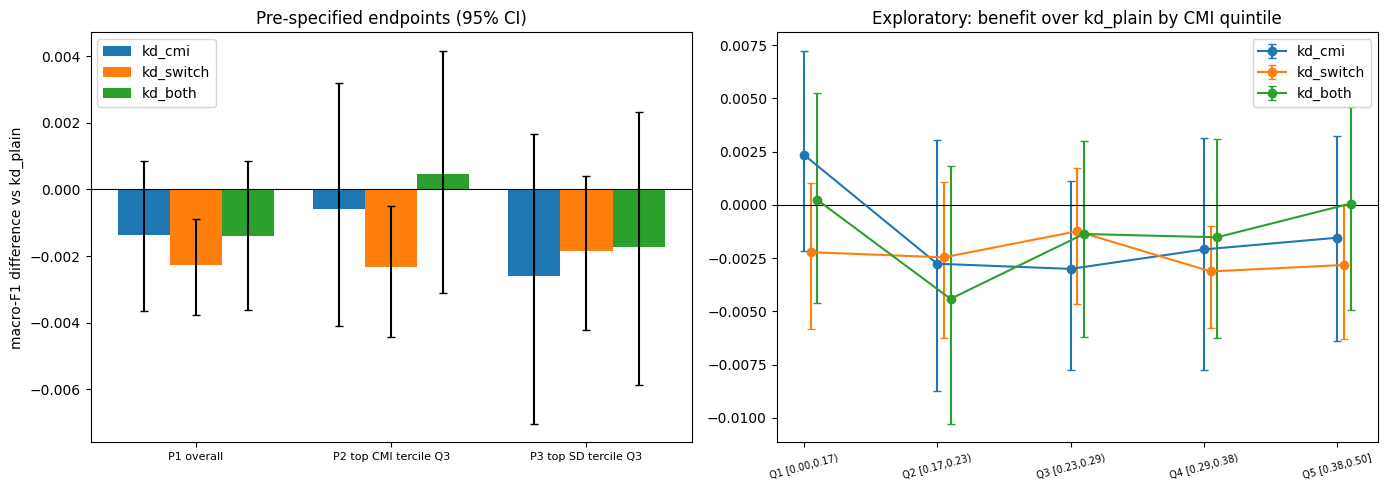

════ PHASE 4 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════
{
  "student_layers": 3,
  "layer_map": [
    3,
    7,
    11
  ],
  "student_params": 30764547,
  "teacher_f1": 0.7337417057843415,
  "arms": [
    "ce_only",
    "kd_plain",
    "kd_cmi",
    "kd_switch",
    "kd_both"
  ],
  "seeds": [
    13,
    42,
    2024
  ],
  "hyperparams": {
    "lambda_cmi": 0.3,
    "w_min": 0.5,
    "w_max": 2.0,
    "mu_switch": 1.0,
    "p_mask_sw": 0.3,
    "n_transfer": 20000,
    "epochs": 3,
    "lr": 5e-05
  },
  "student_test_f1": {
    "ce_only": 0.6937911384499932,
    "kd_plain": 0.712406830757041,
    "kd_cmi": 0.7110652462937771,
    "kd_switch": 0.710144060273957,
    "kd_both": 0.7110314630964526
  },
  "headroom_teacher_minus_kd_plain": [
    0.021606791978676602,
    0.00879646772314516,
    0.033963516920826484
  ]
}
Saved to: phase4_outputs


In [13]:
# CELL 8: Figures + save
# Figures and save.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pdf = prim_df.copy(); eps = list(dict.fromkeys(pdf.endpoint)); w_ = 0.8 / max(1, len(CAND))
for i, a in enumerate(CAND):
    t = pdf[pdf.arm == a].set_index("endpoint").loc[eps]
    ax[0].bar(np.arange(len(eps)) + i * w_, t.Δ_vs_kd_plain, w_, yerr=[t.Δ_vs_kd_plain - t.CI95_lo, t.CI95_hi - t.Δ_vs_kd_plain], capsize=3, label=a)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xticks(np.arange(len(eps)) + w_ * (len(CAND) - 1) / 2); ax[0].set_xticklabels([e.split(" [")[0] for e in eps], fontsize=8)
ax[0].set_ylabel("macro-F1 difference vs kd_plain"); ax[0].set_title("Pre-specified endpoints (95% CI)"); ax[0].legend()
t5 = strat_df[strat_df.cut == "CMI (quintile)"]
for a in CAND:
    ta = t5[t5.arm == a]; ax[1].errorbar(np.arange(len(ta)) + 0.05 * CAND.index(a), ta.delta, yerr=[ta.delta - ta.lo, ta.hi - ta.delta], fmt="o-", capsize=3, label=a)
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xticks(np.arange(len(ta))); ax[1].set_xticklabels(ta.bin, fontsize=7, rotation=15)
ax[1].set_title("Exploratory: benefit over kd_plain by CMI quintile"); ax[1].legend()
plt.tight_layout(); (OUT_DIR / "figures").mkdir(exist_ok=True); plt.savefig(OUT_DIR / "figures" / "phase4_endpoints.png", dpi=150, bbox_inches="tight"); plt.show()

prim_df.to_csv(OUT_DIR / "phase4_primary_endpoints.csv", index=False); strat_df.to_csv(OUT_DIR / "phase4_exploratory_bins.csv", index=False)
for a, p in PROBS_ARM.items(): np.save(OUT_DIR / f"probs_L{STUDENT_LAYERS}_{a}_all_seeds.npy", p)
summary = {"student_layers": STUDENT_LAYERS, "layer_map": LAYER_MAP, "student_params": int(s_par), "teacher_f1": t_f1, "arms": list(PRED_ARM), "seeds": SEEDS,
           "hyperparams": {"lambda_cmi": LAMBDA_CMI, "w_min": W_MIN, "w_max": W_MAX, "mu_switch": MU_SWITCH, "p_mask_sw": P_MASK_SW, "n_transfer": int(len(transfer)), "epochs": EPOCHS, "lr": LR},
           "student_test_f1": {a: float(np.mean([macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(S_[a])])) for a in PRED_ARM},
           "headroom_teacher_minus_kd_plain": [float(np.mean(hd))] + [float(x) for x in ci(hd)]}
(OUT_DIR / "phase4_summary.json").write_text(json.dumps(summary, indent=2))
print("=" * 70); print("════ PHASE 4 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════"); print("=" * 70)
print(json.dumps(summary, indent=2)); print("Saved to:", OUT_DIR)